# Q2: How should a single A/B test be judged?
A complete analysis of one headline test: significance, confidence interval,
bootstrap check, and statistical power.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from google.cloud import bigquery
from scipy import stats
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_confint,
    proportions_ztest,
)
import sys

sys.path.append(str(Path("..").resolve()))
from src.stats.proportions import minimum_detectable_effect, sample_size_per_arm, two_proportion_test
from src.stats.srm import reliable_test_ids
load_dotenv(Path("..") / ".env")
client = bigquery.Client(project=os.environ["GCP_PROJECT_ID"], location="asia-northeast1")

ALPHA = 0.05
POWER = 0.80

In [2]:
balance = client.query("""
    select test_id, started_at, chi_square_stat, degrees_of_freedom
    from `headline-ab-audit.analytics_marts.fct_test_balance`
    where dataset_split = 'exploratory'
""").to_dataframe()
balance["started_at"] = balance["started_at"].dt.tz_localize(None)

reliable_ids = reliable_test_ids(balance, "after window")
print(f"Reliable tests (after window, no SRM): {len(reliable_ids)}")

c:\dev\headline-ab-audit\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Reliable tests (after window, no SRM): 3472


In [3]:
arms = client.query("""
    select *
    from `headline-ab-audit.analytics_marts.fct_arm_results`
    where dataset_split = 'exploratory'
""").to_dataframe()
arms = arms[arms["test_id"].isin(reliable_ids)]

two_arm_tests = arms.loc[arms["n_arms"] == 2, "test_id"].unique()
print(f"Reliable two-arm tests: {len(two_arm_tests)}")

c:\dev\headline-ab-audit\.venv\Lib\site-packages\google\cloud\bigquery\table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Reliable two-arm tests: 80


In [4]:
totals = arms[arms["test_id"].isin(two_arm_tests)].groupby("test_id")["impressions"].sum()
chosen_id = totals.idxmax()

chosen = arms[arms["test_id"] == chosen_id].sort_values("arm_created_at").reset_index(drop=True)
chosen[["arm_created_at", "headline", "impressions", "clicks", "ctr"]]

,arm_created_at,headline,impressions,clicks,ctr
0,2014-02-24 00:32:44.640000+00:00,Here's A Scary Clip Illustrating How Amazingly...,15194,362,0.023825
1,2014-02-24 00:33:03.842000+00:00,Here's A Scary Clip Illustrating How Amazingly...,14970,350,0.023380


In [5]:
a, b = chosen.iloc[0], chosen.iloc[1]
n_a, x_a = int(a["impressions"]), int(a["clicks"])
n_b, x_b = int(b["impressions"]), int(b["clicks"])

result = two_proportion_test(x_a, n_a, x_b, n_b, alpha=ALPHA)
p_a, p_b, p_value = result.ctr_a, result.ctr_b, result.p_value

print(f"CTR  A: {p_a:.3%}  ({x_a:,} / {n_a:,})")
print(f"CTR  B: {p_b:.3%}  ({x_b:,} / {n_b:,})")
print(f"Difference (B - A): {result.diff * 100:+.3f} pp   relative lift: {result.relative_lift:+.1%}")
print(f"95% CI of difference: [{result.ci_low * 100:+.3f}, {result.ci_high * 100:+.3f}] pp")
print(f"z = {result.z_stat:.2f}, p = {p_value:.4f}")

CTR  A: 2.383%  (362 / 15,194)
CTR  B: 2.338%  (350 / 14,970)
Difference (B - A): -0.045 pp   relative lift: -1.9%
95% CI of difference: [-0.387, +0.298] pp
z = -0.25, p = 0.7990


In [6]:
rng = np.random.default_rng(42)
sims_a = rng.binomial(n_a, p_a, size=10_000) / n_a
sims_b = rng.binomial(n_b, p_b, size=10_000) / n_b
boot_low, boot_high = np.percentile(sims_b - sims_a, [2.5, 97.5])

print(f"Bootstrap 95% CI: [{boot_low * 100:+.3f}, {boot_high * 100:+.3f}] pp")

Bootstrap 95% CI: [-0.383, +0.294] pp


In [7]:
pooled = (x_a + x_b) / (n_a + n_b)
mde = minimum_detectable_effect(pooled, n_a, n_b, alpha=ALPHA, power=POWER)
n_needed = sample_size_per_arm(pooled, 0.10, alpha=ALPHA, power=POWER)

print(f"Minimum detectable effect: {mde * 100:.3f} pp ({mde / p_a:.1%} relative to A)")
print(f"Impressions per arm needed to detect a 10% relative lift: {n_needed:,.0f}")

Minimum detectable effect: 0.490 pp (20.6% relative to A)
Impressions per arm needed to detect a 10% relative lift: 64,934


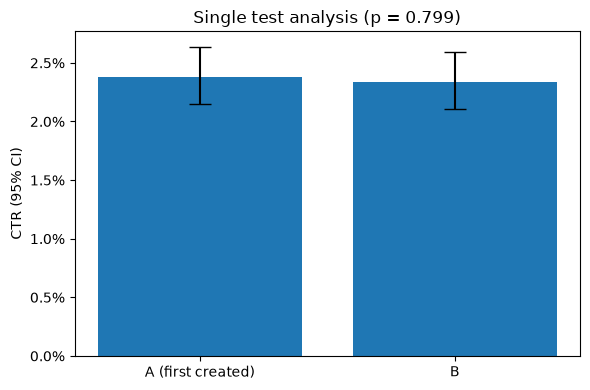

In [8]:
labels = ["A (first created)", "B"]
ctrs = [p_a, p_b]
cis = [proportion_confint(x, n, alpha=ALPHA, method="wilson") for x, n in [(x_a, n_a), (x_b, n_b)]]
errors = np.array([[c - lo, hi - c] for c, (lo, hi) in zip(ctrs, cis)]).T

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(labels, ctrs, yerr=errors, capsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_ylabel("CTR (95% CI)")
ax.set_title(f"Single test analysis (p = {p_value:.3f})")
fig.tight_layout()

Path("../docs/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../docs/figures/q2_single_test.png", dpi=150)
plt.show()

## Q2 findings

**Test selection rule:** among reliable two-arm tests (started after the flagged window,
no SRM), the one with the most impressions. Arm A is the arm created first.

- CTR: A 2.383% vs. B 2.338% (15,194 vs. 14,970 impressions)
- Difference: -0.045 pp (-1.9% relative), 95% CI [-0.387, +0.298] pp, p = 0.799
- Bootstrap 95% CI: [-0.383, +0.294] pp, consistent with the normal approximation
- Minimum detectable effect at 80% power: 0.490 pp (20.6% relative)

**No reliable difference.** The interval includes zero. With this sample, only
differences of 20.6% or more could be detected reliably; detecting a 10% lift
would need about 64,934 impressions per arm, more than four times what this test had.

**Implication:** this is the largest reliable two-arm test, so the other two-arm tests
had even less power. A "winner" picked from tests of this size is likely to reflect noise
rather than a real difference, which Q3 examines directly.